# Transporte óptimo vía Sinkhorn

Este cuaderno presenta el **transporte óptimo entrópico**, calculado con el algoritmo de Sinkhorn (`ot.sinkhorn` en POT), y lo compara con el transporte óptimo **exacto** (`ot.emd`), que usamos como referencia. Usamos solo esas dos herramientas de POT.

**¿Qué es `ot.emd`?** La sigla EMD viene de *Earth Mover's Distance* ("distancia del movedor de tierra"), el nombre que se le dio en visión por computadora a la distancia de Wasserstein-1 entre histogramas. POT la usa en un sentido más amplio: `ot.emd(a, b, M)` resuelve el problema de transporte óptimo exacto (el programa lineal de Kantorovich, con el algoritmo de *network simplex*) para **cualquier** matriz de costos `M`, y devuelve un plan óptimo; `ot.emd2` devuelve su costo, que es $W_p^p$ cuando $M_{ij}=d(x_i,y_j)^p$ (la notación se introduce más abajo). Por eso "EMD" no es una distancia sino el nombre del *solver exacto*.

**¿En qué sentido es exacto?** Es exacto para el **problema discreto** que se le da: *network simplex* es un método finito (recorre vértices del politopo de planes admisibles y termina en un vértice óptimo), sin parámetro de regularización ni tolerancia que ajustar. El resultado es óptimo salvo la precisión de máquina (`float64`), siempre que termine antes de `numItermax`; si no, POT avisa con un `warning` y devuelve un plan que no es óptimo. Que sea exacto para el problema discreto no significa que lo sea para el problema que uno quiere aproximar (por ejemplo, la grilla discretiza una densidad o las muestras representan una imagen).

Los pasos:

0. Un problema en 1D donde conocemos bien la respuesta, y una explicación de qué hace el algoritmo de Sinkhorn.
1. Cómo cambia el **plan** de transporte con $\varepsilon$.
2. Cuánto **error** cometemos en el valor al regularizar.
3. Cuánto **cuesta** usar $\varepsilon$ chico, y qué variante del algoritmo conviene.
4. Cómo **escalan** los dos métodos con el número de puntos.
5. Una **aplicación**: transferencia de color entre dos imágenes.

## Notación

Trabajamos con medidas discretas $\mu=\sum_{i=1}^n a_i\,\delta_{x_i}$ y $\nu=\sum_{j=1}^m b_j\,\delta_{y_j}$, donde $a\in\mathbb R^n$ y $b\in\mathbb R^m$ son vectores de pesos (probabilidades). Dado un costo $c(x,y)$, la **matriz de costos** es $M_{ij}=c(x_i,y_j)$ y el conjunto de planes admisibles es

$$U(a,b)=\{P\in\mathbb R^{n\times m}:\ P\ge 0,\ P\mathbf 1=a,\ P^\top\mathbf 1=b\}.$$

- **Problema exacto.** `ot.emd` devuelve un plan óptimo $P^*$ y `ot.emd2` el valor $W=\min_{P\in U(a,b)}\langle P,M\rangle$. Si $c(x,y)=d(x,y)^p$, entonces $W=W_p^p(\mu,\nu)$: ojo, `emd2` devuelve la distancia de Wasserstein **elevada a la $p$**, no $W_p$.
- **Problema entrópico.** `ot.sinkhorn` devuelve el plan $P_\varepsilon$, minimizador de
$$W_\varepsilon=\min_{P\in U(a,b)}\ \langle P,M\rangle+\varepsilon\,\mathrm{KL}(P\,|\,a\otimes b),\qquad \mathrm{KL}(P\,|\,a\otimes b)=\sum_{ij}P_{ij}\log\frac{P_{ij}}{a_ib_j}.$$

Dos aclaraciones. (i) $W_\varepsilon$ es el *valor del funcional regularizado*, no una distancia (por ejemplo, $W_\varepsilon(\mu,\mu)>0$). (ii) POT escribe la regularización como $\sum_{ij}P_{ij}\log P_{ij}$, que difiere de la KL en una constante que solo depende de $a$ y $b$: el plan $P_\varepsilon$ es el mismo.

**Convención de este cuaderno.** El costo se llama $c(x,y)$. El parámetro de regularización se expresa de manera relativa, $\varepsilon=\widetilde{\varepsilon}\cdot\max M$ (en el código, `eps_rel`), para que los valores de $\widetilde{\varepsilon}$ sean comparables entre problemas con distinta escala de costos.

In [ ]:
%pip install -q pot

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
import ot

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("POT", ot.__version__)

POT 0.9.7.post1


## 0. Setup: dos medidas en 1D

Dos medidas discretas sobre la **misma grilla** de $n=100$ puntos de $[0,1]$ (es decir, $x_i=y_i$: las dos medidas comparten soporte). $\mu$ es una gaussiana discretizada y $\nu$ una mezcla de dos gaussianas. El costo es $c(x,y)=|x-y|^2$, así que el valor exacto es $W_2^2$. Con $n$ chico, `emd` es instantáneo y nos da la **referencia** contra la cual medir todo.

W_2^2 exacto = 0.064272   (entradas no nulas del plan: 176 de 10000)


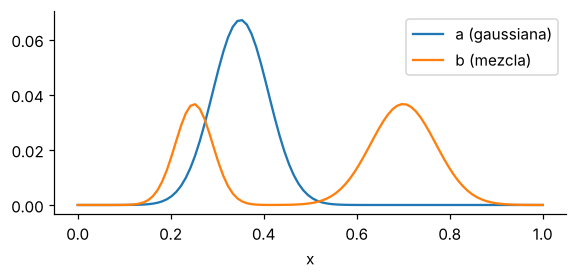

In [2]:
n = 100
x = np.linspace(0, 1, n)                  # grilla: x_i = y_i

def gauss(m, s): return np.exp(-0.5 * ((x - m) / s) ** 2)

a = gauss(0.35, 0.06)
a = a / a.sum()                           # pesos de probabilidad: suman 1
b = 0.5 * gauss(0.25, 0.04) + 0.5 * gauss(0.70, 0.07)
b = b / b.sum()

# x[:, None] pasa x de forma (100,) a (100, 1): ot.dist espera una matriz de puntos, uno por fila
M = ot.dist(x[:, None], x[:, None])       # M_ij = |x_i - y_j|^2
P_star = ot.emd(a, b, M)                  # plan exacto
W = ot.emd2(a, b, M)                      # valor exacto = W_2^2
print(f"W_2^2 exacto = {W:.6f}   (entradas no nulas del plan: {(P_star > 1e-12).sum()} de {n*n})")

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.plot(x, a, label="a (gaussiana)"); ax.plot(x, b, label="b (mezcla)")
ax.legend(); ax.set_xlabel("x"); plt.show()

**Observación (para otros $p$).** `emd2` devuelve $W_p^p$ cuando `M` contiene $d(x,y)^p$. Para puntos `X`, `Y` en $\mathbb R^d$: `M = ot.dist(X, Y)**(p/2)` (porque `ot.dist` ya devuelve $|x-y|^2$) y `Wp = ot.emd2(a, b, M)**(1/p)`.

### Antes de seguir: ¿qué hace el algoritmo de Sinkhorn?

**Qué da la teoría y qué no.** $U(a,b)$ es compacto y convexo, y el funcional $P\mapsto\langle P,M\rangle+\varepsilon\,\mathrm{KL}(P\,|\,a\otimes b)$ es continuo y estrictamente convexo. Por compacidad el minimizador $P_\varepsilon$ existe, y por convexidad estricta es único. Pero ese argumento no dice **cómo calcularlo**.

**La forma del minimizador.** Se introducen multiplicadores $f\in\mathbb R^n$ y $g\in\mathbb R^m$ para las restricciones de filas y de columnas:

$$L(P,f,g)=\sum_{ij}P_{ij}M_{ij}+\varepsilon\sum_{ij}P_{ij}\log\frac{P_{ij}}{a_ib_j}-\sum_if_i\Big(\sum_jP_{ij}-a_i\Big)-\sum_jg_j\Big(\sum_iP_{ij}-b_j\Big).$$

La restricción $P\ge 0$ no hace falta imponerla: la derivada de $P\log P$ vale $-\infty$ en $0$, así que el minimizador es **estrictamente positivo**. Derivando respecto de $P_{ij}$ e igualando a cero,

$$M_{ij}+\varepsilon\Big(\log\frac{P_{ij}}{a_ib_j}+1\Big)-f_i-g_j=0\ \Longrightarrow\ P_{ij}=u_i\,K_{ij}\,v_j,\qquad K_{ij}=e^{-M_{ij}/\varepsilon},$$

con $u_i=a_ie^{f_i/\varepsilon-1/2}$ y $v_j=b_je^{g_j/\varepsilon-1/2}$. Como el problema es convexo, estas condiciones son necesarias y suficientes: **cualquier** $P=\mathrm{diag}(u)\,K\,\mathrm{diag}(v)$ que cumpla las restricciones de marginales es el minimizador. El problema se reduce entonces a encontrar $u,v>0$ tales que

$$u\odot(Kv)=a,\qquad v\odot(K^\top u)=b,$$

donde $\odot$ es el producto de Hadamard (componente a componente: $(u\odot w)_i=u_iw_i$). De la misma manera, los cocientes de vectores que aparecen más abajo, como $b/(K^\top u)$ y $a/(Kv)$, son **componente a componente**: $(a/w)_i=a_i/w_i$. El par $(u,v)$ no es único: $(\lambda u,v/\lambda)$ da el mismo $P$.

**El algoritmo.** El sistema es no lineal en $(u,v)$ conjuntamente, pero **lineal en cada uno si se fija el otro**. Entonces se alterna: se arranca con $u=\mathbf 1$; dado $u$, se despeja $v=b/(K^\top u)$, que cumple la segunda ecuación exactamente; dado $v$, se despeja $u=a/(Kv)$, que cumple la primera exactamente; y se repite. Cada paso es una proyección (en sentido KL) sobre uno de los dos conjuntos afines $\{P\mathbf 1=a\}$ y $\{P^\top\mathbf 1=b\}$: reescalar las columnas, o reescalar las filas. Sinkhorn son entonces **proyecciones alternadas** que parten de $K$ y conservan la forma $\mathrm{diag}(u)\,K\,\mathrm{diag}(v)$ en todo momento.

**Convergencia.** La convergencia es lineal, pero la razón empeora cuando $\varepsilon\to 0$: hacen falta más iteraciones (lo vamos a medir en la sección 3). Después de actualizar $u$ la restricción de filas se cumple exacta, y el criterio de parada (`stopThr`) mide cuánto se aparta la de columnas.

**Verificación.** Si $\varepsilon\to\infty$, $K\to$ matriz de unos y $P=a\otimes b$: el plan independiente. Lo vamos a ver en la sección 1.

In [3]:
def sinkhorn_desde_cero(a, b, M, eps, n_iter):
    K = np.exp(-M / eps)                  # núcleo de Gibbs: K_ij = exp(-M_ij / eps)
    u = np.ones(len(a))
    for _ in range(n_iter):
        v = b / (K.T @ u)                 # cociente componente a componente; ajusta las columnas: v ⊙ (Kᵀ u) = b
        u = a / (K @ v)                   # cociente componente a componente; ajusta las filas:    u ⊙ (K v)  = a
    return u[:, None] * K * v[None, :]    # P = diag(u) K diag(v)

eps = 0.1 * M.max()                       # un epsilon moderado
P_mio = sinkhorn_desde_cero(a, b, M, eps, n_iter=500)
P_pot = ot.sinkhorn(a, b, M, eps, method="sinkhorn", numItermax=10_000, stopThr=1e-12)

print(f"máx |P_mío - P_POT|            = {np.abs(P_mio - P_pot).max():.1e}")
print(f"error del marginal a (filas)    = {np.abs(P_mio.sum(axis=1) - a).sum():.1e}")
print(f"error del marginal b (columnas) = {np.abs(P_mio.sum(axis=0) - b).sum():.1e}")

máx |P_mío - P_POT|            = 2.3e-15
error del marginal a (filas)    = 1.7e-16
error del marginal b (columnas) = 3.3e-16


Para $\varepsilon$ chico el núcleo $K=e^{-M/\varepsilon}$ se vuelve numéricamente inmanejable. En esos casos vamos a usar **la misma iteración calculada en el dominio logarítmico** (`method="sinkhorn_log"`); en la sección 3 se explica por qué hace falta y qué cuesta.

### Funciones auxiliares

`sinkhorn_plan` fija la variante logarítmica y una tolerancia estricta (la usamos en las secciones 1 y 2). `entropic_value` evalúa el funcional regularizado $\langle P,M\rangle+\varepsilon\,\mathrm{KL}(P\,|\,a\otimes b)$, que es $W_\varepsilon$ cuando $P=P_\varepsilon$.

In [4]:
def sinkhorn_plan(a, b, M, reg):
    # versión en el dominio log: aguanta epsilon chicos
    return ot.sinkhorn(a, b, M, reg, method="sinkhorn_log", numItermax=200_000, stopThr=1e-10)

def kl_to_product(P, a, b):
    R = np.outer(a, b)                    # R_ij = a_i b_j
    m = P > 0                             # convención 0 log 0 = 0: solo entradas positivas
    return np.sum(P[m] * np.log(P[m] / R[m]))

def entropic_value(P, M, a, b, reg):
    # valor del funcional regularizado en P:  <P,M> + reg * KL(P | a⊗b)
    return np.sum(P * M) + reg * kl_to_product(P, a, b)

## 1. ¿Cómo es el plan?

Dibujamos los planes como mapas de calor, con **el origen $x$ en el eje horizontal y el destino $y$ en el vertical** (se dibuja $P^\top$; así el plan exacto se ve como el gráfico de un mapa $y=T(x)$). El píxel $(x_i,y_j)$ se pinta según $P_{ij}$: más oscuro, más masa.

De izquierda a derecha: el plan producto $a\otimes b$ (el límite $\varepsilon\to\infty$), los planes de Sinkhorn para $\widetilde{\varepsilon}=1,\ 0.1,\ 0.01,\ 0.001,\ 0.0001$ y el plan exacto de `emd`. Recordar que $\varepsilon=\widetilde{\varepsilon}\cdot\max M$, y como acá $\max M=1$, numéricamente $\varepsilon=\widetilde{\varepsilon}$.

En cada título se informa $\|P-P^*\|_F/\|P^*\|_F$, la norma de Frobenius relativa de la diferencia con el plan exacto. Mide diferencias **entrada por entrada**, no cercanía geométrica. Cada panel normaliza su propia escala de color (el máximo de cada matriz es el azul más oscuro).

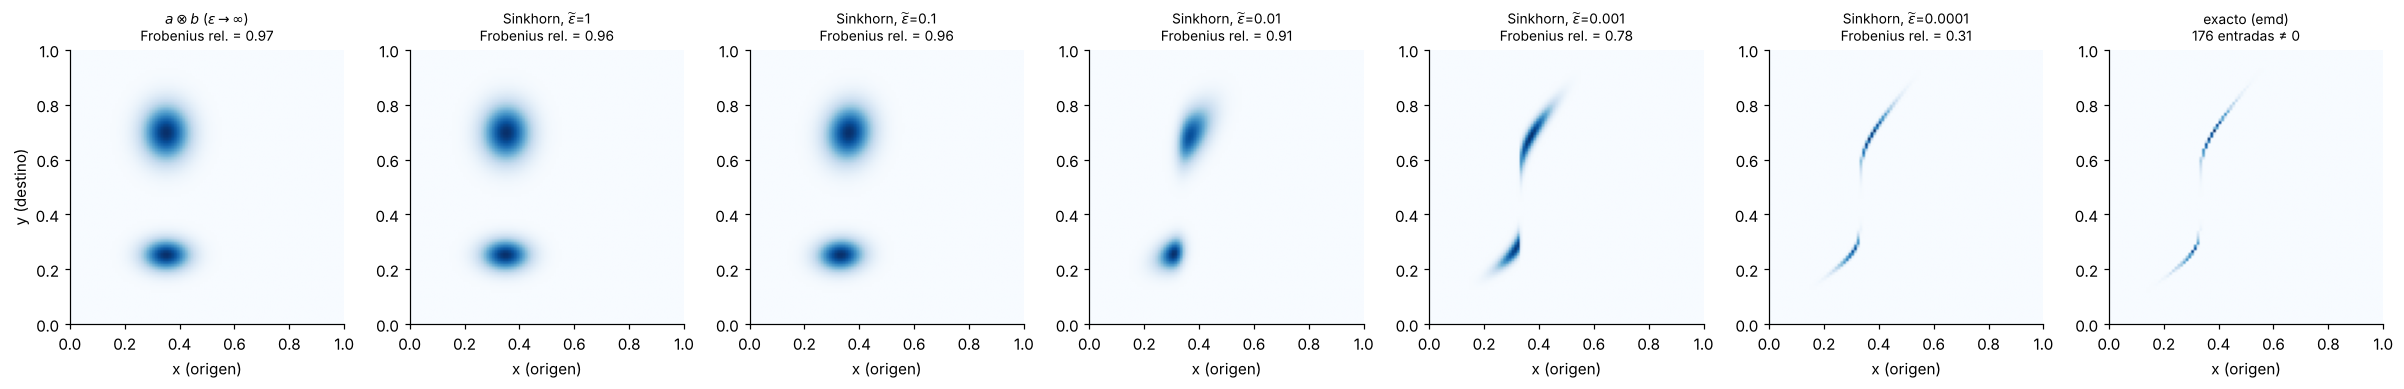

In [5]:
eps_rels = [1, 0.1, 0.01, 0.001, 0.0001]
planes = [np.outer(a, b)] + [sinkhorn_plan(a, b, M, e * M.max()) for e in eps_rels] + [P_star]
names = [r"$a\otimes b$ ($\varepsilon\to\infty$)"] + [rf"Sinkhorn, $\widetilde{{\varepsilon}}$={e}" for e in eps_rels] + ["exacto (emd)"]

def rel_frob(P): return np.linalg.norm(P - P_star) / np.linalg.norm(P_star)    # Frobenius relativa

fig, axes = plt.subplots(1, 7, figsize=(22, 3.4))
for ax, P, name in zip(axes, planes, names):
    ax.imshow(P.T, origin="lower", extent=[0, 1, 0, 1], cmap="Blues")        # P.T: x horizontal, y vertical
    info = f"{(P > 1e-12).sum()} entradas ≠ 0" if P is P_star else f"Frobenius rel. = {rel_frob(P):.2f}"
    ax.set_title(name + "\n" + info, fontsize=9)
    ax.set_xlabel("x (origen)")
axes[0].set_ylabel("y (destino)")
plt.tight_layout(); plt.show()

### La misma figura con una escala de color común (logarítmica)

Arriba cada panel tenía su propia escala. Acá se usa **un único rango para todos**, logarítmico, de $10^{-12}$ al máximo. Se ve así la amplitud relativa de los planes y su soporte completo. En **gris** se marcan las entradas que valen exactamente 0 en `float64`. Para el plan exacto son ceros estructurales (el plan óptimo es disperso). Para Sinkhorn, en cambio, en aritmética exacta $P_{ij}>0$ siempre; los ceros que aparecen para $\widetilde{\varepsilon}$ chico son **subflujo** (*underflow*): valores positivos menores que el mínimo representable ($\approx10^{-308}$) que se redondean a 0.

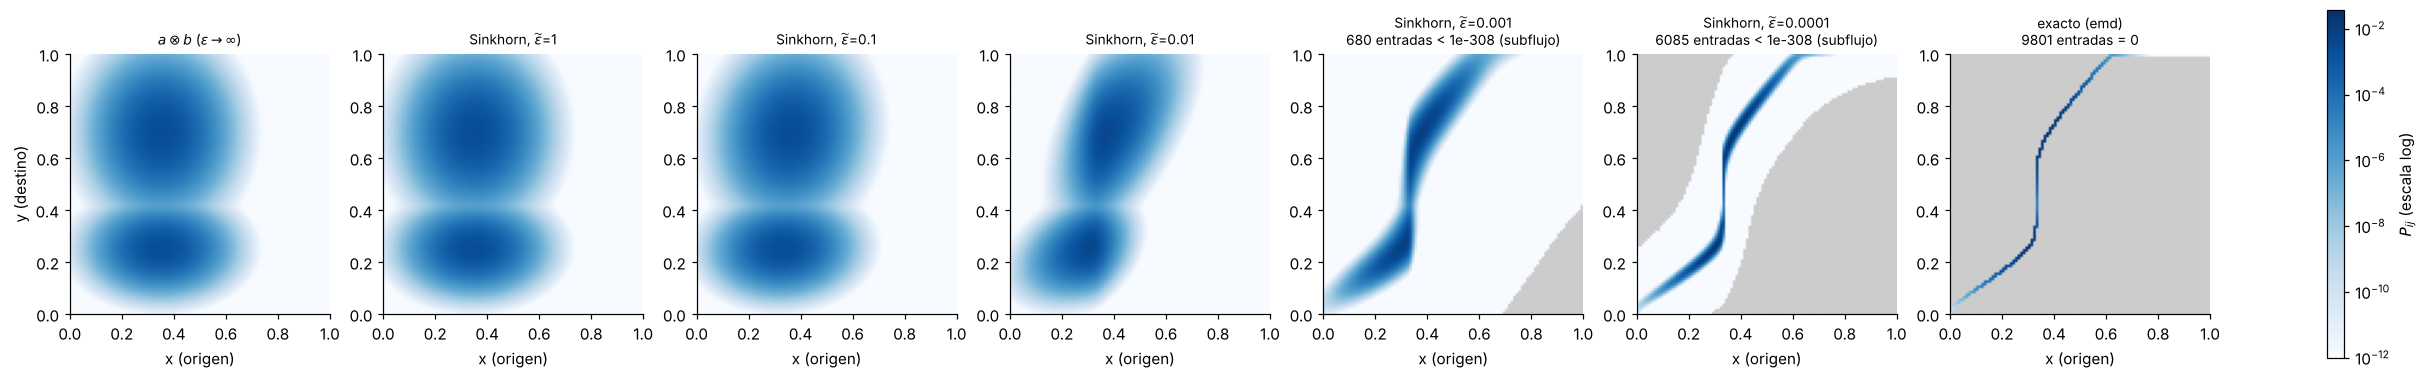

In [6]:
from matplotlib.colors import LogNorm

vmax = max(P.max() for P in planes)
cmap_log = plt.get_cmap("Blues").copy(); cmap_log.set_bad("0.8")          # gris: ceros en float64

fig, axes = plt.subplots(1, 7, figsize=(22, 3.8), layout="constrained")
for ax, P, name in zip(axes, planes, names):
    im = ax.imshow(np.ma.masked_less_equal(P, 0).T, origin="lower", extent=[0, 1, 0, 1],
                   cmap=cmap_log, norm=LogNorm(vmin=1e-12, vmax=vmax))
    k = (P == 0).sum()
    extra = "" if k == 0 else (f"\n{k} entradas = 0" if P is P_star else f"\n{k} entradas < 1e-308 (subflujo)")
    ax.set_title(name + extra, fontsize=9); ax.set_xlabel("x (origen)")
axes[0].set_ylabel("y (destino)")
fig.colorbar(im, ax=axes, shrink=0.85, label="$P_{ij}$ (escala log)")
plt.show()

**Pregunta 1.**
(a) ¿A qué plan se parece el de $\widetilde{\varepsilon}=1$ y por qué?
(b) ¿Qué le pasa al soporte del plan cuando $\varepsilon\to0$? ¿Qué relación tiene el plan exacto con un mapa de transporte $T$ (¿es el gráfico de una función?) y por qué se ve monótono en 1D?
(c) En la figura logarítmica, ¿qué diferencia estructural hay entre el plan exacto y los de Sinkhorn, y a qué se debe?

## 2. ¿Cuánto error cometo en el valor?

Para cada $\varepsilon$ medimos dos cosas distintas:

- el **costo del plan regularizado**, $\langle P_\varepsilon, M\rangle$, que es lo que devuelve `ot.sinkhorn2`;
- el **valor del funcional regularizado**, $W_\varepsilon=\langle P_\varepsilon,M\rangle+\varepsilon\,\mathrm{KL}(P_\varepsilon\,|\,a\otimes b)$.

Los dos se comparan con el valor exacto $W$. Como $\mathrm{KL}\ge 0$ y $P_\varepsilon\in U(a,b)$, ambos quedan por encima de $W$.

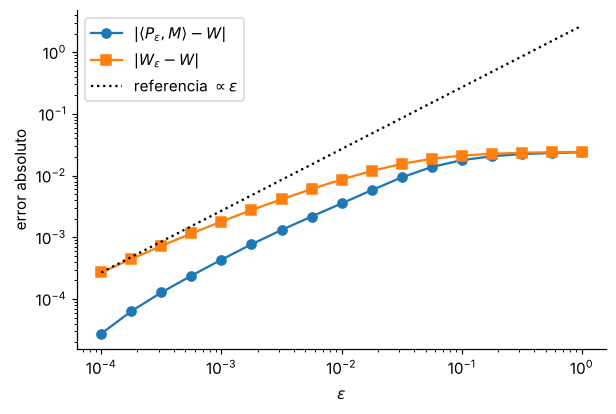

In [7]:
eps_rels = np.logspace(-4, 0, 17)
err_lin, err_val = [], []
for eps_rel in eps_rels:
    eps = eps_rel * M.max()
    P = sinkhorn_plan(a, b, M, eps)
    err_lin.append(abs(np.sum(P * M) - W))
    err_val.append(abs(entropic_value(P, M, a, b, eps) - W))

fig, ax = plt.subplots(figsize=(6.2, 4))
eps_arr = eps_rels * M.max()
ax.loglog(eps_arr, err_lin, "o-", label=r"$|\langle P_\varepsilon,M\rangle - W|$")
ax.loglog(eps_arr, err_val, "s-", label=r"$|W_\varepsilon - W|$")
ax.loglog(eps_arr, eps_arr * (err_val[0] / eps_arr[0]), "k:", label=r"referencia $\propto\varepsilon$")
ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("error absoluto"); ax.legend()
plt.show()

**Pregunta 2.** ¿Cuál de las dos curvas baja más rápido al achicar $\varepsilon$? ¿Cuánto vale la pendiente de cada una en el tramo $\varepsilon\in[10^{-3},10^{-1}]$ y en el tramo final? ¿Qué es lo que domina el error de $W_\varepsilon$? (Pista: mirá el término $\varepsilon\,\mathrm{KL}(P_\varepsilon\,|\,a\otimes b)$ cuando $\varepsilon\to0$.) ¿Cuál es el precio de achicar $\varepsilon$ (sección siguiente)?

## 3. ¿Cuánto cuesta $\varepsilon$ chico?

Achicar $\varepsilon$ tiene **dos efectos distintos**:

1. El algoritmo necesita **más iteraciones**: la contracción de las proyecciones alternadas es más lenta cuando $K=e^{-M/\varepsilon}$ está muy desbalanceado. Es un problema de *velocidad*.
2. La versión estándar de las iteraciones se vuelve **numéricamente inestable**: $K$ y los escalamientos $u,v$ se salen del rango de `float64`. Es un problema de *precisión de la aritmética*.

Para medir el primero usamos `method="sinkhorn_log"` (las mismas iteraciones calculadas en el dominio logarítmico; más abajo se explica). POT evalúa el criterio de parada cada 10 iteraciones, así que el número de iteraciones que informa es siempre un múltiplo de 10 (el "10" del tramo plano es un piso del chequeo).

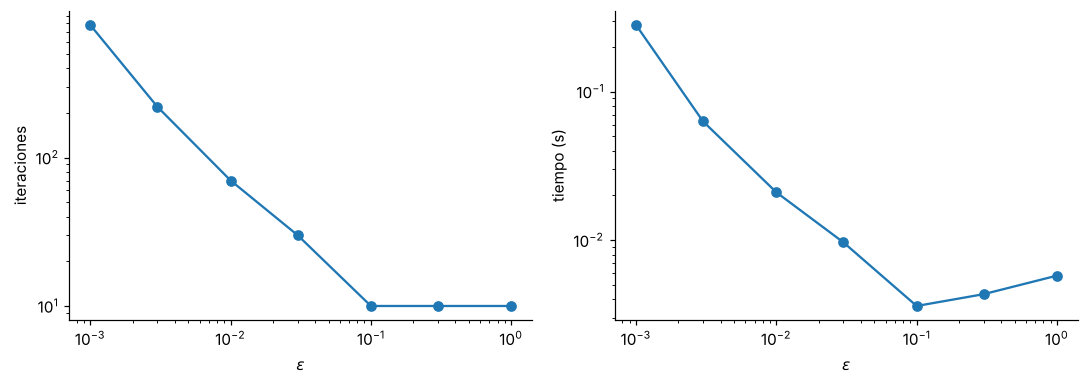

In [8]:
eps_rels = [1, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001]
iters, times = [], []
for eps_rel in eps_rels:
    t = time.perf_counter()
    P, log = ot.sinkhorn(a, b, M, eps_rel * M.max(), method="sinkhorn_log",
                         numItermax=500_000, stopThr=1e-10, log=True)
    times.append(time.perf_counter() - t)
    iters.append(log.get("niter", np.nan))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].loglog(np.array(eps_rels) * M.max(), iters, "o-"); axes[0].set_ylabel("iteraciones")
axes[1].loglog(np.array(eps_rels) * M.max(), times, "o-"); axes[1].set_ylabel("tiempo (s)")
for ax in axes: ax.set_xlabel(r"$\varepsilon$")
plt.tight_layout(); plt.show()

### La versión estándar y la versión logarítmica

**`method="sinkhorn"`** (la variante por defecto) es la iteración tal como la escribimos: calcula $K=e^{-M/\varepsilon}$ una vez y alterna $v\leftarrow b/(K^\top u)$, $u\leftarrow a/(Kv)$. Cada iteración son dos productos matriz-vector, así que es **rápida**. Pero si $\varepsilon$ es chico, $e^{-M_{ij}/\varepsilon}$ se redondea a 0 cuando $M_{ij}/\varepsilon\gtrsim745$ (subflujo en `float64`) y $u,v$ se desbordan: aparecen divisiones por cero e infinitos.

**`method="sinkhorn_log"`** hace **las mismas iteraciones** pero con los potenciales $f=\varepsilon\log u$ y $g=\varepsilon\log v$:

$$g_j\leftarrow \varepsilon\log b_j-\varepsilon\,\mathrm{LSE}_i\Big(\frac{f_i-M_{ij}}{\varepsilon}\Big),\qquad f_i\leftarrow \varepsilon\log a_i-\varepsilon\,\mathrm{LSE}_j\Big(\frac{g_j-M_{ij}}{\varepsilon}\Big),$$

con $\mathrm{LSE}(z)=\log\sum_k e^{z_k}$ calculado restando el máximo (log-sum-exp), y arma el plan al final con $P_{ij}=\exp\big((f_i+g_j-M_{ij})/\varepsilon\big)$. Es **estable** para $\varepsilon$ muy chico, pero cada iteración exige exponenciales y logaritmos sobre toda la matriz, así que es **más lenta** (en pruebas con $n=2000$, del orden de decenas de veces).

Probamos los dos métodos con el mismo $\varepsilon$: ¿cumple el plan que devuelven la restricción del segundo marginal? (POT avisa del problema con un `warning` pero no da error; acá lo silenciamos para ver solo la tabla.)

In [9]:
def error_marginal(P, b):
    return np.abs(P.sum(axis=0) - b).sum()        # ¿P^T 1 = b?  (norma l1 de la diferencia)

filas = []
for eps_rel in [1e-2, 1e-3, 2e-4, 1e-4]:
    eps = eps_rel * M.max()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        P_std = ot.sinkhorn(a, b, M, eps, method="sinkhorn",     numItermax=50_000, stopThr=1e-9)
        P_log = ot.sinkhorn(a, b, M, eps, method="sinkhorn_log", numItermax=50_000, stopThr=1e-9)
    filas.append((eps_rel, error_marginal(P_std, b), error_marginal(P_log, b)))

print("Error del marginal b, ||P^T 1 - b||_1   (0 = plan válido; máximo posible = 2)")
print(f"{'eps_rel':<10}{'sinkhorn':<12}{'sinkhorn_log':<14}")
for eps_rel, e_std, e_log in filas:
    print(f"{eps_rel:<10}{e_std:<12.1e}{e_log:<14.1e}")

Error del marginal b, ||P^T 1 - b||_1   (0 = plan válido; máximo posible = 2)
eps_rel   sinkhorn    sinkhorn_log  
0.01      2.0e-09     2.0e-09       
0.001     5.7e-09     5.7e-09       
0.0002    1.1e+00     5.6e-09       
0.0001    1.4e+00     5.7e-09       


**Pregunta 3.** ¿Por qué no podemos simplemente tomar $\varepsilon=10^{-8}$? Pista: mirá el núcleo $K=e^{-M/\varepsilon}$ y la aritmética de punto flotante. ¿Qué arregla `sinkhorn_log` y a qué costo?

**Otras variantes que existen** (no las usamos): `"sinkhorn_stabilized"` (absorbe los escalamientos en los potenciales cuando crecen demasiado), `"sinkhorn_epsilon_scaling"` (resuelve una secuencia de problemas con $\varepsilon$ decreciente) y `"greenkhorn"` (actualiza una sola fila o columna por iteración).

**Qué método usamos en cada sección:**

| Sección | Método | Motivo |
|---|---|---|
| 1 y 2 | `sinkhorn_log` | necesitamos llegar a $\widetilde{\varepsilon}=10^{-4}$ con $n=100$ |
| 3 (iteraciones y tiempo) | `sinkhorn_log` | idem |
| 3 (tabla de marginales) | los dos | es la comparación |
| 4 y 5 | `sinkhorn` (estándar) | $n$ grande y $\varepsilon$ moderado: la versión log sería mucho más lenta |

## 4. ¿Por qué no usamos solo `emd`?

Ahora puntos en $\mathbb R^3$ (como los colores RGB de una imagen). No hay fórmula cerrada y la matriz de costos es $n\times n$. Medimos el tiempo de `emd2` y de `sinkhorn2` (versión estándar, la de `method` por defecto) con $\varepsilon=0.05\,\max M$, para $n$ creciente. Cada tiempo es **una sola medición** (sin repetir), así que para $n$ chico hay ruido; las pendientes se ajustan con $n\ge2000$.

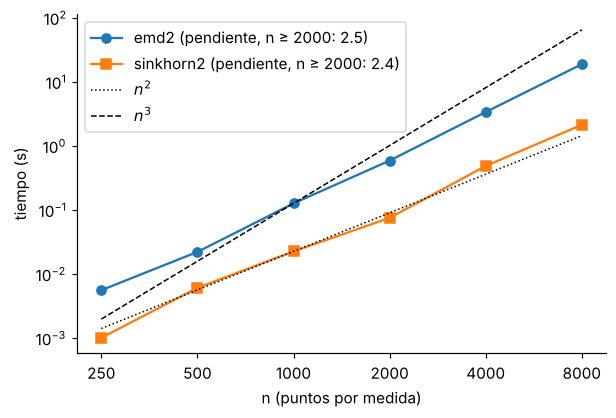

Memoria solo de la matriz de costos n×n (float64, 8 bytes por entrada):
  n =   1,000:        0.01 GB
  n =   4,000:        0.13 GB
  n =  10,000:        0.80 GB
  n =  30,000:        7.20 GB
  n = 100,000:       80.00 GB
  n = 273,000:      596.23 GB


In [10]:
rng = np.random.default_rng(0)
ns = [250, 500, 1000, 2000, 4000, 8000]
t_emd, t_sk = [], []
for n_ in ns:
    X = rng.normal(size=(n_, 3))
    Y = rng.normal(size=(n_, 3)) + 0.5
    w = np.ones(n_) / n_
    Mn = ot.dist(X, Y)                                   # no se cronometra: es igual para los dos métodos
    t = time.perf_counter(); ot.emd2(w, w, Mn, numItermax=10**8); t_emd.append(time.perf_counter() - t)
    t = time.perf_counter(); ot.sinkhorn2(w, w, Mn, 0.05 * Mn.max(), numItermax=1000, stopThr=1e-6); t_sk.append(time.perf_counter() - t)

ns_a, t_emd, t_sk = np.array(ns), np.array(t_emd), np.array(t_sk)
big = ns_a >= 2000                                       # pendiente en el régimen de n grande
s_emd = np.polyfit(np.log(ns_a[big]), np.log(t_emd[big]), 1)[0]
s_sk = np.polyfit(np.log(ns_a[big]), np.log(t_sk[big]), 1)[0]

fig, ax = plt.subplots(figsize=(6.2, 4))
ax.loglog(ns_a, t_emd, "o-", label=f"emd2 (pendiente, n ≥ 2000: {s_emd:.1f})")
ax.loglog(ns_a, t_sk, "s-", label=f"sinkhorn2 (pendiente, n ≥ 2000: {s_sk:.1f})")
i0 = ns.index(1000)
ax.loglog(ns_a, t_sk[i0] * (ns_a / 1000) ** 2, "k:", lw=1, label="$n^2$")
ax.loglog(ns_a, t_emd[i0] * (ns_a / 1000) ** 3, "k--", lw=1, label="$n^3$")
ax.set_xticks(ns_a); ax.set_xticklabels(ns_a); ax.minorticks_off()
ax.set_xlabel("n (puntos por medida)"); ax.set_ylabel("tiempo (s)"); ax.legend()
plt.show()

print("Memoria solo de la matriz de costos n×n (float64, 8 bytes por entrada):")
for n_ in [1000, 4000, 10_000, 30_000, 100_000, 273_000]:
    print(f"  n = {n_:>7,}:  {8 * n_**2 / 1e9:10.2f} GB")

**Pregunta 4.** ¿Hasta qué $n$ llegarías con 1 minuto de cálculo con cada método (extrapolá con las pendientes medidas; ojo, para $n$ chico dominan costos fijos y la pendiente engaña)? ¿Qué pasa con la memoria antes de que el tiempo sea el problema? Fijate en la última fila: es el número de píxeles de una foto de $427\times 640$.

## 5. Aplicación: transferencia de color

**Problema.** Tenemos una imagen *fuente* y una *destino*. Queremos pintar la fuente con la paleta de colores del destino, preservando su estructura.

**Modelo.** Cada imagen es una nube de píxeles en el cubo de colores RGB $\subset\mathbb R^3$: descartamos la posición del píxel y nos quedamos con su color. Cada nube es una medida empírica con pesos uniformes, $\mu=\frac1n\sum_i\delta_{x_i}$ y $\nu=\frac1n\sum_j\delta_{y_j}$, con costo $c(x,y)=|x-y|^2$ entre colores. El plan óptimo entre $\mu$ y $\nu$ dice a qué colores destino va cada color fuente.

**El problema de escala.** La imagen tiene 273 280 píxeles, lo que daría una matriz de costos de ~600 GB (ver sección 4). Por eso **submuestreamos** $n=2000$ colores por imagen; el transporte se resuelve sobre esas muestras y después se extiende a todos los píxeles.

**Pasos.** (1) preparar los datos; (2) calcular el plan exacto (`emd`) y los planes entrópicos (Sinkhorn); (3) ver que un plan no es un mapa; (4) definir la *proyección baricéntrica* para obtener un mapa y pintar; (5) comparar los resultados.

In [11]:
from sklearn.datasets import load_sample_images
from scipy.spatial import cKDTree

imgs = load_sample_images().images
src, tgt = imgs[0] / 255.0, imgs[1] / 255.0              # china.jpg (fuente) -> flower.jpg (paleta destino)
Xs_all, Xt_all = src.reshape(-1, 3), tgt.reshape(-1, 3)  # cada fila es el color RGB de un píxel
print(f"píxeles por imagen: {len(Xs_all):,};  matriz completa: {8 * len(Xs_all)**2 / 1e9:.0f} GB")

rng = np.random.default_rng(1)
n_px = 2000
Xs = Xs_all[rng.choice(len(Xs_all), n_px, replace=False)]   # colores x_i de la fuente
Xt = Xt_all[rng.choice(len(Xt_all), n_px, replace=False)]   # colores y_j del destino
w = np.ones(n_px) / n_px                                    # pesos uniformes: a_i = b_j = 1/n_px
Mc = ot.dist(Xs, Xt)                                        # M_ij = |x_i - y_j|^2 en RGB

píxeles por imagen: 273,280;  matriz completa: 597 GB


### Paso 2: el plan exacto y los planes entrópicos

Para Sinkhorn usamos la versión estándar (`method="sinkhorn"`): con $n=2000$ y $\widetilde{\varepsilon}\ge10^{-3}$ funciona y es mucho más rápida que la logarítmica.

In [12]:
planes_color, tiempos = {}, {}

t = time.perf_counter()                              # plan exacto: la referencia, primero
planes_color["emd (exacto)"] = ot.emd(w, w, Mc, numItermax=10**8)
tiempos["emd (exacto)"] = time.perf_counter() - t

for eps_rel in [0.1, 0.01, 0.001]:                   # después Sinkhorn, de epsilon grande a chico
    t = time.perf_counter()
    P = ot.sinkhorn(w, w, Mc, eps_rel * Mc.max(), method="sinkhorn", numItermax=20_000, stopThr=1e-6)
    name = f"Sinkhorn, eps_rel={eps_rel}"
    planes_color[name] = P
    tiempos[name] = time.perf_counter() - t

### Paso 3: el problema, un plan no es un mapa

Para pintar necesitamos, a cada color fuente $x_i$, asignarle **un** color de salida. Pero un plan $P$ puede repartir la masa de $x_i$ entre muchos colores destino $y_j$. ¿Cuántos? Contamos, para cada fila $i$, cuántas entradas superan $10^{-8}$ (las filas suman $1/n=5\times10^{-4}$).

- Con `emd`, como las dos medidas tienen $n$ átomos de peso $1/n$, el plan exacto es una **permutación**: cada $x_i$ manda toda su masa a un único $y_{\sigma(i)}$. Es un mapa de transporte (de Monge).
- Con Sinkhorn el plan es **denso**: cada $x_i$ reparte masa entre muchos $y_j$. No es un mapa.

In [13]:
print(f"{'plan':<30}{'entradas > 1e-8 por fila (promedio)'}")
for name, P in planes_color.items():
    print(f"{name:<30}{(P > 1e-8).sum(axis=1).mean():.1f}")

plan                          entradas > 1e-8 por fila (promedio)
emd (exacto)                  1.0
Sinkhorn, eps_rel=0.1         1866.8
Sinkhorn, eps_rel=0.01        1019.8
Sinkhorn, eps_rel=0.001       377.8


### Paso 4: la proyección baricéntrica

Para obtener un mapa a partir de un plan que reparte masa, a cada $x_i$ se le asigna el **promedio** de los colores destino, pesado por lo que el plan le manda a cada uno:

$$T(x_i)=\frac{\sum_jP_{ij}\,y_j}{\sum_jP_{ij}}.$$

Es el promedio de la distribución condicional de destinos de $x_i$ (la fila $i$ del plan normalizada), y se llama *proyección baricéntrica*. **No tiene relación con el baricentro de Wasserstein** (el minimizador de $\sum_k\lambda_kW_2^2(\mu_k,\cdot)$ entre varias medidas): acá no se promedian medidas, sino los puntos de destino de una sola fila del plan.

Para el plan exacto (una permutación) da simplemente $T(x_i)=y_{\sigma(i)}$. Para Sinkhorn mezcla colores del destino, y mezcla más cuanto mayor es $\varepsilon$.

Como el transporte se resolvió solo sobre los 2000 colores muestreados, para pintar toda la imagen cada píxel toma el color de salida de **su color muestreado más cercano** (vecino más cercano en el espacio RGB, con un `cKDTree`).

In [14]:
def proyeccion_baricentrica(P, Xt):
    # T[i] = sum_j P[i,j] * Xt[j] / sum_j P[i,j]: promedio de los colores destino de x_i, pesado por la fila i
    return (P @ Xt) / P.sum(axis=1, keepdims=True)

tree = cKDTree(Xs)
_, nn = tree.query(Xs_all)          # para cada píxel, el índice del color muestreado más cercano (en RGB)

def pintar(T):
    # cada píxel toma el nuevo color de su vecino muestreado; se rearma la imagen
    return np.clip(T[nn].reshape(src.shape), 0, 1)

colores_nuevos = {name: proyeccion_baricentrica(P, Xt) for name, P in planes_color.items()}
imagenes = {name: pintar(T) for name, T in colores_nuevos.items()}

### Paso 5: resultados

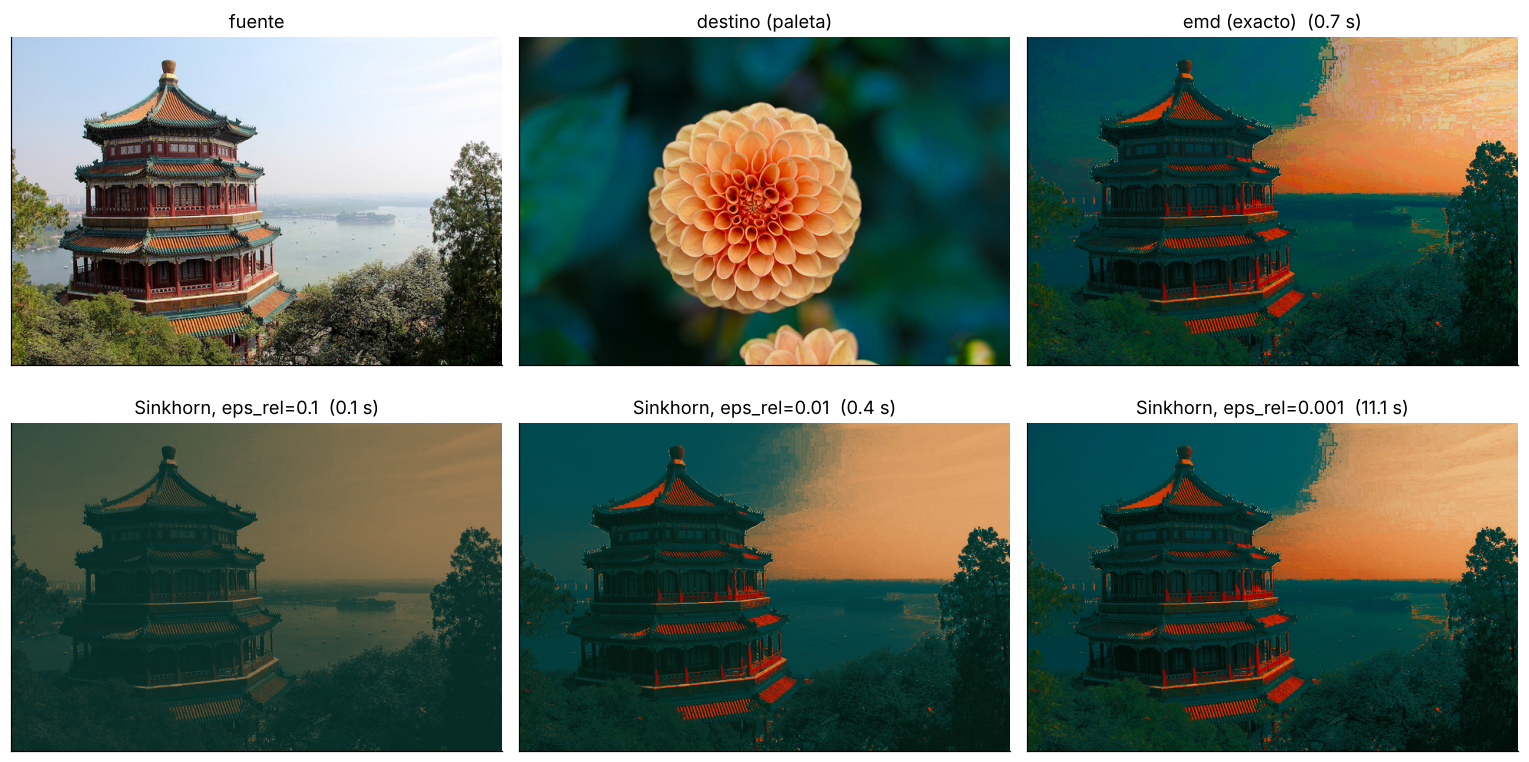

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.4))
axes[0, 0].imshow(src); axes[0, 0].set_title("fuente")
axes[0, 1].imshow(tgt); axes[0, 1].set_title("destino (paleta)")
panels = [axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]]
for ax, (name, img) in zip(panels, imagenes.items()):
    ax.imshow(img); ax.set_title(f"{name}  ({tiempos[name]:.1f} s)")
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Las nubes de colores

Cada punto es **un color** de los 2000 muestreados, ubicado según sus coordenadas R (horizontal) y G (vertical) y pintado con su color real (es una proyección del cubo RGB que ignora el canal azul). Arriba: la paleta del **destino** ($y_j$) y los **colores nuevos** que la proyección baricéntrica del plan exacto le asigna a los colores de la fuente. Como el plan exacto es una permutación, estos colores nuevos son exactamente los del destino, y la nube coincide con la primera. Abajo: los colores nuevos con los planes de Sinkhorn, de $\widetilde{\varepsilon}=0.1$ a $0.001$.

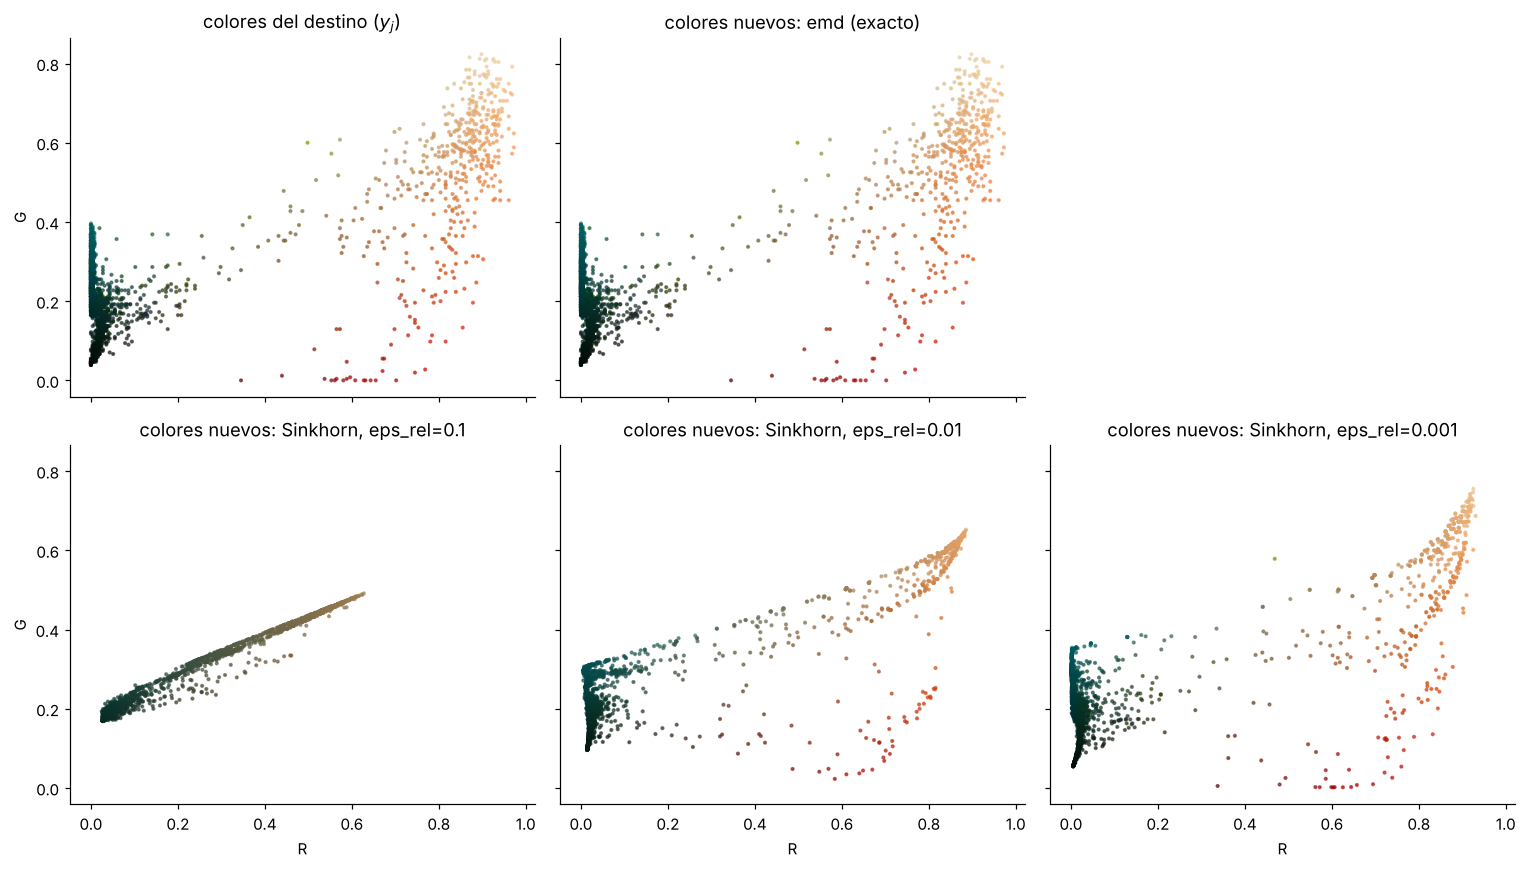

In [16]:
# Nubes de colores en el plano R-G (se ignora el canal B): cada punto es un color, pintado con su color real
nombres = ["emd (exacto)", "Sinkhorn, eps_rel=0.1", "Sinkhorn, eps_rel=0.01", "Sinkhorn, eps_rel=0.001"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
axes[0, 0].scatter(Xt[:, 0], Xt[:, 1], s=3, c=Xt, alpha=.6)
axes[0, 0].set_title("colores del destino ($y_j$)")
paneles = [axes[0, 1], axes[1, 0], axes[1, 1], axes[1, 2]]
for ax, name in zip(paneles, nombres):
    T_ = colores_nuevos[name]
    ax.scatter(T_[:, 0], T_[:, 1], s=3, c=np.clip(T_, 0, 1), alpha=.6)
    ax.set_title("colores nuevos: " + name)
axes[0, 2].axis("off")                          # el sexto panel queda vacío
for ax in axes[1]: ax.set_xlabel("R")
for ax in axes[:, 0]: ax.set_ylabel("G")
plt.tight_layout(); plt.show()

**Pregunta 5.** Compará las imágenes y las nubes de colores nuevos.

- ¿Qué diferencia hay entre `emd` y Sinkhorn con $\widetilde{\varepsilon}=0.001$? ¿Y entre $\widetilde{\varepsilon}=0.001$ y $0.1$?
- ¿Por qué con $\varepsilon$ grande los colores "se aplastan" hacia el promedio del destino? (Pensá en el plan de la sección 1 y en la proyección baricéntrica.)
- Las manchas en bloques del cielo vienen de extender el mapa con el vecino más cercano entre solo 2000 colores muestreados. ¿Cómo las reducirías?
- Con esta aplicación, ¿qué $\varepsilon$ elegirías y por qué? ¿Cambiaría la respuesta si en lugar de 2000 usáramos 20 000 colores por imagen?

## Resumen

| | `emd` | Sinkhorn |
|---|---|---|
| Resultado | exacto, plan disperso | aproximado, plan denso y suave |
| Costo (tiempo) | entre $n^{2.5}$ y $n^3$ (peor caso $O(n^3\log n)$) | $\sim n^2$ por iteración |
| Memoria | $n^2$ | $n^2$ |
| Parámetro | ninguno | $\varepsilon$: sesgo vs. velocidad y estabilidad |
| Diferenciable | no (en general) | sí |